# Dá para "adivinhar" o Overall de uma carta do FIFA só olhando os atributos dela?
## Projeto de Ciência de Dados — Inteligência Artificial e Ciência de Dados / PUCPR

Todo jogador do FIFA tem um **Overall**: aquele número grande no canto da carta (o 91 do Messi, o 89 do Van Dijk).
A EA chega nesse número a partir dos atributos do jogador (finalização, passe, reflexos, desarme…), mas a fórmula
exata não é pública.

**A pergunta deste projeto:** se mostrarmos a um computador só os atributos de um jogador, ele consegue descobrir
o Overall com precisão? Se sim, qual é a melhor forma de "ensinar" isso a ele?

Em ciência de dados chamamos isso de **modelo de regressão**: um programa que aprende com milhares de exemplos
(jogadores cujo Overall já conhecemos) e depois estima o Overall de jogadores que ele nunca viu.

---
### Como ler este material
Cada etapa segue o mesmo roteiro: **o que vamos testar → o resultado → o que isso significa**.
Não é preciso entender o código: os textos e as frases impressas abaixo de cada bloco resumem tudo.

**As três "notas" que usamos para avaliar os modelos:**

| Medida | Em linguagem de FIFA | O que é bom |
|---|---|---|
| **MAE** (erro médio) | "Em média, o modelo erra o Overall da carta por quantos pontos?" Ex.: MAE = 0,6 → erra menos de 1 ponto | quanto **menor**, melhor |
| **RMSE** (erro com peso para os grandes erros) | Parecido com o MAE, mas "pune mais" quando o modelo erra feio, por exemplo dizer 80 para um jogador 88 | quanto **menor**, melhor |
| **R²** (quanto o modelo explica) | De 0 a 1 (ou 0% a 100%): quanto da diferença entre jogadores fracos e craques o modelo consegue explicar | quanto **mais perto de 1**, melhor |

> Este trabalho continua o projeto de *Análise e Preparação de Dados* (`Projeto_FIFA23.ipynb`), que já
> explorou a base. Aqui fazemos as análises extras que faltavam para prever o Overall.

# 0. Preparação do ambiente
Carregamos as ferramentas que vamos usar (bibliotecas do Python) e indicamos onde está o arquivo com os jogadores.

In [ ]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from statsmodels.stats.outliers_influence import variance_inflation_factor

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:          # se o XGBoost não estiver instalado, usamos um modelo equivalente do scikit-learn
    HAS_XGB = False

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RNG = 42   # "semente" fixa: garante que quem rodar de novo obtém exatamente os mesmos resultados

# Onde está a base: funciona tanto com o arquivo só do FIFA 23 quanto com a base completa (FIFA 15 a 23)
_cands = [
    r"C:\\male_players.csv",
    r"C:\\male_players_fifa23.csv",
    "../data/male_players.csv", "../data/male_players_fifa23.csv",
    "male_players.csv", "male_players_fifa23.csv", "data.csv",
]
CSV_PATH = next((p for p in _cands if Path(p).exists()), _cands[0])

# A base completa tem ~10 milhões de linhas: pesado demais para um notebook.
# Se for o caso, sorteamos uma quantidade de JOGADORES (com todas as edições de cada um).
SAMPLE_PLAYERS = 60_000      # None = usar todos
TARGET = "overall"           # o que queremos prever
print("Arquivo usado:", CSV_PATH)

# 1. Carregando os jogadores

A base tem 110 colunas, mas nem todas interessam (link da foto, número da camisa…). Lemos só as necessárias e
em formato compacto. Isso deixa o arquivo várias vezes mais leve na memória do computador, o que é essencial
quando se trabalha com a base completa de 10 milhões de linhas.

In [3]:
# Ratings por posição (ST, CB, GK…), aquele número que aparece ao mudar o jogador de posição no jogo
POS_RATINGS = ["ls", "st", "rs", "lw", "lf", "cf", "rf", "rw", "lam", "cam", "ram", "lm", "lcm", "cm",
               "rcm", "rm", "lwb", "ldm", "cdm", "rdm", "rwb", "lb", "lcb", "cb", "rcb", "rb", "gk"]
# Os 34 atributos detalhados que aparecem na tela de detalhes do jogador
DETAILED = [
    "attacking_crossing", "attacking_finishing", "attacking_heading_accuracy", "attacking_short_passing",
    "attacking_volleys", "skill_dribbling", "skill_curve", "skill_fk_accuracy", "skill_long_passing",
    "skill_ball_control", "movement_acceleration", "movement_sprint_speed", "movement_agility",
    "movement_reactions", "movement_balance", "power_shot_power", "power_jumping", "power_stamina",
    "power_strength", "power_long_shots", "mentality_aggression", "mentality_interceptions",
    "mentality_positioning", "mentality_vision", "mentality_penalties", "mentality_composure",
    "defending_marking_awareness", "defending_standing_tackle", "defending_sliding_tackle",
    "goalkeeping_diving", "goalkeeping_handling", "goalkeeping_kicking", "goalkeeping_positioning",
    "goalkeeping_reflexes",
]
FACE = ["pace", "shooting", "passing", "dribbling", "defending", "physic"]   # os 6 números da frente da carta
MARKET = ["potential", "value_eur", "wage_eur", "release_clause_eur", "international_reputation"]
BASIC = ["age", "height_cm", "weight_kg", "weak_foot", "skill_moves", "league_level"]
CATS = ["preferred_foot", "work_rate", "body_type", "player_positions", "league_name"]
IDS = ["player_id", "fifa_version", "fifa_update", "short_name"]

USECOLS = IDS + [TARGET] + DETAILED + FACE + MARKET + BASIC + CATS + POS_RATINGS + ["goalkeeping_speed"]
dtypes = {c: "float32" for c in DETAILED + FACE + MARKET + BASIC + ["goalkeeping_speed"]}
dtypes.update({c: "category" for c in ["preferred_foot", "work_rate", "body_type", "league_name"]})

df = pd.read_csv(CSV_PATH, usecols=lambda c: c in USECOLS, dtype=dtypes, low_memory=False)
print(f"{len(df):,} registros carregados, ocupando {df.memory_usage(deep=True).sum() / 1e6:.0f} MB de memória")

# Agrupamos as posições como no jogo: Goleiro (GK), Defesa (DEF), Meio-campo (MID) e Ataque (FWD)
POSITION_GROUP = {"GK": "GK",
                  **dict.fromkeys(["CB", "RB", "LB", "RWB", "LWB"], "DEF"),
                  **dict.fromkeys(["CDM", "CM", "CAM", "RM", "LM"], "MID"),
                  **dict.fromkeys(["RW", "LW", "CF", "ST", "RF", "LF"], "FWD")}
df["primary_pos"] = df["player_positions"].astype(str).str.split(",").str[0].str.strip()
df["position_group"] = df["primary_pos"].map(POSITION_GROUP).astype("category")
df["is_gk"] = (df["position_group"] == "GK").astype("int8")

18,127 registros carregados, ocupando 11 MB de memória


### 1.1 Uma carta por jogador em cada edição
Durante uma temporada, a EA atualiza as cartas várias vezes (os *updates* de janela de transferência, por exemplo).
Na base completa, isso faz o mesmo jogador aparecer repetido quase igual dentro do mesmo FIFA. Guardamos só a
**última versão da carta** de cada jogador em cada edição, para nenhum jogador "contar dobrado".

In [4]:
n0 = len(df)
df = (df.sort_values(["player_id", "fifa_version", "fifa_update"])
        .drop_duplicates(["player_id", "fifa_version"], keep="last")
        .reset_index(drop=True))
print(f"Antes: {n0:,} registros | depois de remover cartas repetidas: {len(df):,}")

if SAMPLE_PLAYERS is not None and df["player_id"].nunique() > SAMPLE_PLAYERS:
    keep = pd.Series(df["player_id"].unique()).sample(SAMPLE_PLAYERS, random_state=RNG)
    df = df[df["player_id"].isin(keep)].reset_index(drop=True)
    print(f"Sorteamos {SAMPLE_PLAYERS:,} jogadores -> {len(df):,} cartas")

EDITIONS = sorted(df["fifa_version"].unique())
MULTI_EDITION = len(EDITIONS) > 1
print(f"Edições na base: {', '.join(f'FIFA {e}' for e in EDITIONS)} | jogadores diferentes: {df['player_id'].nunique():,}")

Antes: 18,127 registros | depois de remover cartas repetidas: 18,127
Edições na base: FIFA 23 | jogadores diferentes: 18,127


# 2. Conhecendo o Overall antes de prever

Antes de colocar o computador para aprender, precisamos entender **como o Overall se comporta**. Cada análise abaixo
responde uma pergunta que, mais à frente, vira uma decisão sobre como montar o modelo.

| # | Pergunta | Por que importa |
|---|---|---|
| 2.1 | Goleiros, zagueiros, meias e atacantes têm Overall parecido? | Decide se um único modelo serve para todos |
| 2.2 | Quais atributos mais "puxam" o Overall, e isso muda por posição? | Mostra o que o modelo precisa enxergar |
| 2.3 | Existe alguma coluna que "entrega a resposta"? | Evita um modelo que parece ótimo, mas trapaceia |
| 2.4 | Há atributos que dizem a mesma coisa? | Evita informação repetida e confusa |
| 2.5 | Por que alguns jogadores têm campos vazios? | Decide como tratar os buracos na base |
| 2.6 | Quantos craques existem? | Mostra onde o modelo tende a errar mais |
| 2.7 | O mesmo jogador aparece mais de uma vez? | Define como testar o modelo de forma justa |

### 2.1 O Overall muda conforme a posição?

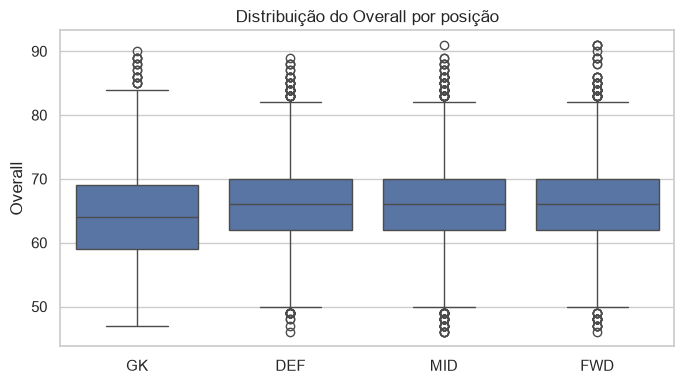

                Overall médio  menor  maior  nº de jogadores
position_group                                              
DEF                      66.0     46     89             6116
FWD                      66.0     46     91             3488
GK                       64.4     47     90             2039
MID                      65.9     46     91             6484


In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="position_group", y=TARGET, order=["GK", "DEF", "MID", "FWD"], ax=ax)
ax.set(title="Distribuição do Overall por posição", xlabel="", ylabel="Overall")
plt.tight_layout(); plt.show()

resumo = df.groupby("position_group", observed=True)[TARGET].agg(["mean", "min", "max", "count"]).round(1)
resumo.columns = ["Overall médio", "menor", "maior", "nº de jogadores"]
print(resumo)

**O que isso significa:** o Overall médio é parecido em todas as posições (por volta de 65). Ou seja, ser goleiro
ou atacante não deixa a carta "mais forte" ou "mais fraca" por si só. O que muda é **quais atributos formam essa
nota**, e isso é o que a próxima análise mostra.

### 2.2 Quais atributos mais "puxam" o Overall?
Medimos a **correlação** de cada atributo com o Overall: um número de −1 a 1 que diz o quanto os dois sobem juntos.
Perto de 1, quando o atributo sobe, o Overall quase sempre sobe junto. Perto de 0, um não tem nada a ver com o outro.
Fazemos isso para a base inteira e separado por posição.

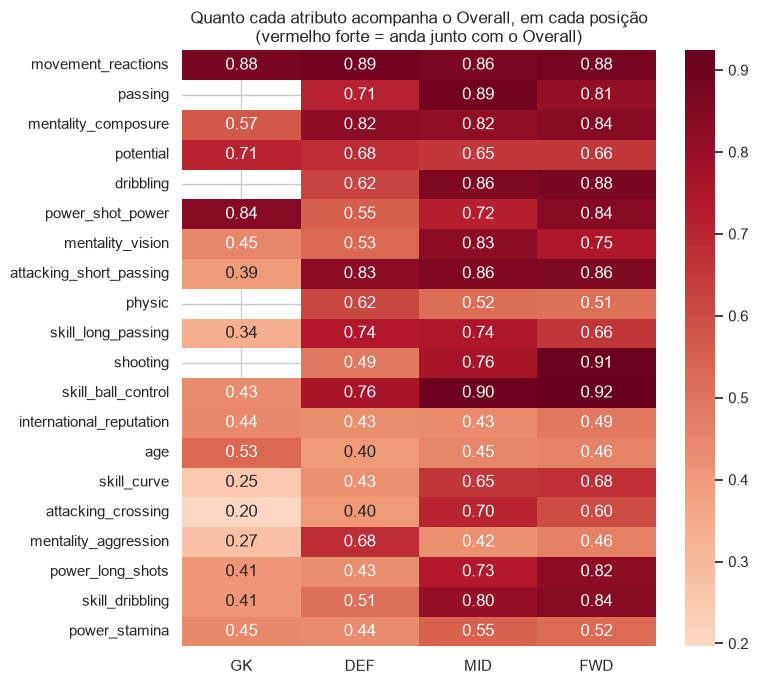

Atributo que mais acompanha o Overall em qualquer posição: movement_reactions (correlação 0.87)
  GK: atributos mais ligados ao Overall -> goalkeeping_reflexes, goalkeeping_diving, goalkeeping_positioning
  DEF: atributos mais ligados ao Overall -> defending, mentality_interceptions, movement_reactions
  MID: atributos mais ligados ao Overall -> skill_ball_control, passing, movement_reactions
  FWD: atributos mais ligados ao Overall -> skill_ball_control, shooting, mentality_positioning


In [6]:
num_feats = DETAILED + FACE + BASIC + ["potential", "international_reputation"]
corr_all = df[num_feats + [TARGET]].corr()[TARGET].drop(TARGET)
by_pos = {g: d[num_feats + [TARGET]].corr()[TARGET].drop(TARGET)
          for g, d in df.groupby("position_group", observed=True)}
corr_tbl = pd.DataFrame({"todos": corr_all, **{g: s for g, s in by_pos.items()}})
corr_tbl = corr_tbl.sort_values("todos", key=abs, ascending=False)

top = corr_tbl.head(20).index
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(corr_tbl.loc[top, ["GK", "DEF", "MID", "FWD"]], annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title="Quanto cada atributo acompanha o Overall, em cada posição\n(vermelho forte = anda junto com o Overall)")
plt.tight_layout(); plt.show()

print(f"Atributo que mais acompanha o Overall em qualquer posição: {corr_tbl.index[0]} "
      f"(correlação {corr_tbl['todos'].iloc[0]:.2f})")
for g in ["GK", "DEF", "MID", "FWD"]:
    print(f"  {g}: atributos mais ligados ao Overall -> {', '.join(by_pos[g].dropna().sort_values(ascending=False).head(3).index)}")

**O que isso significa:** **Reações** (`movement_reactions`) é importante para todo mundo. Fora isso, cada posição
tem a sua própria "receita": no goleiro, mandam os atributos de goleiro; no atacante, finalização e controle de bola;
no zagueiro, desarme e marcação. É como se a EA usasse **uma fórmula diferente para cada posição**.

**Decisão:** o modelo precisa saber a posição do jogador e precisa conseguir combinar posição + atributo
("chute só pesa muito se for atacante"). Modelos mais simples, que somam os atributos sempre com o mesmo peso,
vão ter dificuldade; modelos baseados em **árvores de decisão** fazem esse tipo de combinação naturalmente.

### 2.3 Tem alguma coluna que "entrega a resposta"?
Em ciência de dados chamamos isso de **vazamento**: dar ao modelo uma informação que já contém a resposta.
É como fazer uma prova com o gabarito do lado: a nota sai ótima, mas não prova que o aluno sabe a matéria.
Na base do FIFA, três grupos de colunas são suspeitos:

1. **Rating por posição** (o número que aparece quando você troca o jogador de posição no jogo): é o próprio Overall
   recalculado para outra posição.
2. **Valor de mercado, salário e multa rescisória:** a EA calcula esses valores *a partir* do Overall.
3. **Potencial:** nunca é menor que o Overall e, para jogadores mais velhos, costuma ser igual a ele.

[1] O melhor rating por posição fica a no máximo 1 ponto do Overall em 87% dos jogadores (correlação 0.99) -> é praticamente o gabarito.
[3] Potencial é maior ou igual ao Overall em 100% dos jogadores e exatamente igual em 34%.


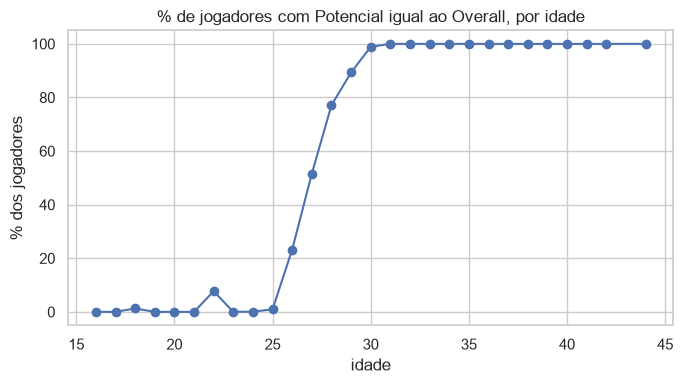

In [7]:
pos_num = df[POS_RATINGS].apply(lambda s: pd.to_numeric(s.astype(str).str.extract(r"^(\d+)")[0], errors="coerce"))
best_pos = pos_num.max(axis=1)
print(f"[1] O melhor rating por posição fica a no máximo 1 ponto do Overall em "
      f"{((best_pos - df[TARGET]).abs() <= 1).mean():.0%} dos jogadores "
      f"(correlação {best_pos.corr(df[TARGET]):.2f}) -> é praticamente o gabarito.")
print(f"[3] Potencial é maior ou igual ao Overall em {(df['potential'] >= df[TARGET]).mean():.0%} dos jogadores "
      f"e exatamente igual em {(df['potential'] == df[TARGET]).mean():.0%}.")

fig, ax = plt.subplots(figsize=(7, 4))
eq = df.assign(igual=(df["potential"] == df[TARGET])).groupby("age")["igual"].mean() * 100
eq.plot(ax=ax, marker="o")
ax.set(title="% de jogadores com Potencial igual ao Overall, por idade", ylabel="% dos jogadores", xlabel="idade")
plt.tight_layout(); plt.show()
df = df.drop(columns=POS_RATINGS)

**O que isso significa:** a partir dos ~29 anos, quase todo jogador tem Potencial igual ao Overall: para esses
jogadores, o Potencial **é** a resposta. Por isso:
- os **ratings por posição** são descartados de vez;
- **Potencial, valor, salário e reputação** ficam fora do modelo principal. Mesmo assim, testamos um segundo cenário
  com eles (seção 3.2), só para mostrar o tamanho da "vantagem injusta" que dariam.

### 2.4 Há atributos que dizem a mesma coisa?
Os 6 números da frente da carta (Ritmo, Chute, Passe, Drible, Defesa, Físico) são **médias dos atributos
detalhados**. Ritmo, por exemplo, é basicamente Aceleração + Velocidade. Dar as duas coisas ao modelo é como
contar a mesma informação duas vezes.

Medimos isso com o **VIF**, um indicador de repetição: acima de 10 já é considerado muita sobreposição.

In [8]:
vif_cols = [c for c in DETAILED if not c.startswith("goalkeeping")] + FACE
Xv = df.loc[df["is_gk"] == 0, vif_cols].dropna().sample(min(5000, (df["is_gk"] == 0).sum()), random_state=RNG)
Xv = (Xv - Xv.mean()) / Xv.std()
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])], index=vif_cols)
print("Atributos mais 'repetidos' (VIF; acima de 10 já é alto):")
print(vif.sort_values(ascending=False).head(8).round(0).astype(int).to_string())

Atributos mais 'repetidos' (VIF; acima de 10 já é alto):
defending              3172
shooting               2298
pace                   1416
passing                1172
physic                 1131
dribbling              1070
attacking_finishing     629
power_strength          493


**O que isso significa:** os 6 números da frente da carta têm VIF na casa dos milhares: são informação 100% repetida.
**Decisão:** usamos só os 34 atributos detalhados, que são mais completos, e deixamos os 6 da frente da carta de fora.

### 2.5 Por que alguns jogadores têm campos vazios?

In [9]:
miss_face = df[FACE].isna().any(axis=1)
print(f"{miss_face.mean():.1%} dos jogadores não têm Ritmo/Chute/Passe/Drible/Defesa/Físico preenchidos.")
print(f"Desses, {df.loc[miss_face, 'is_gk'].mean():.0%} são goleiros.")
print(f"O atributo 'goalkeeping_speed' está vazio em {df['goalkeeping_speed'].isna().mean():.0%} dos jogadores (só existe para goleiro).")

11.2% dos jogadores não têm Ritmo/Chute/Passe/Drible/Defesa/Físico preenchidos.
Desses, 100% são goleiros.
O atributo 'goalkeeping_speed' está vazio em 89% dos jogadores (só existe para goleiro).


**O que isso significa:** os campos vazios não são erro na base. Carta de goleiro simplesmente não tem Ritmo,
Chute etc.: no jogo, ela mostra Mergulho, Manejo, Reflexos… Apagar esses jogadores seria jogar fora todos os goleiros.

**Decisão:** como os 6 números da frente da carta já saíram (item 2.4), o problema desaparece sem precisar
"inventar" valores. Também removemos o `goalkeeping_speed` (quase todo vazio) e criamos uma marcação "é goleiro?",
para o modelo saber qual receita aplicar.

### 2.6 Quantos craques existem?

In [10]:
bins, labels = [0, 59, 69, 79, 100], ["<60", "60-69", "70-79", "80+"]
df["overall_bin"] = pd.cut(df[TARGET], bins=bins, labels=labels)
dist = (df["overall_bin"].value_counts(normalize=True).reindex(labels) * 100).round(1)
for faixa, pct in dist.items():
    print(f"Overall {faixa:>6}: {pct:5.1f}% dos jogadores")

Overall    <60:  16.6% dos jogadores
Overall  60-69:  55.0% dos jogadores
Overall  70-79:  25.6% dos jogadores
Overall    80+:   2.8% dos jogadores


**O que isso significa:** a carta "ouro rara" de verdade (80+) é só uma fatia pequena da base; a maioria está entre
60 e 79. O modelo aprende com muito mais exemplos de jogadores medianos do que de craques, então **é natural que
erre mais com as estrelas**. Por isso, no fim, mostramos o erro separado por faixa de Overall, e não só a média geral.

### 2.7 O mesmo jogador aparece mais de uma vez?

In [11]:
reps = df.groupby("player_id").size()
print(f"{reps.size:,} jogadores diferentes; {(reps > 1).mean():.0%} aparecem em mais de uma edição do FIFA.")

18,127 jogadores diferentes; 0% aparecem em mais de uma edição do FIFA.


**O que isso significa:** na base completa, o mesmo jogador aparece em várias edições (o Messi do FIFA 21, do 22,
do 23…). Se o modelo estudar o Messi do FIFA 22 e depois for testado no Messi do FIFA 23, ele estaria "colando".
**Decisão:** em todos os testes, um jogador fica **inteiro** de um lado só: ou no estudo, ou na prova.

# 3. Preparando os dados para o modelo

### 3.1 Criando informações novas a partir das existentes

In [12]:
df["bmi"] = df["weight_kg"] / (df["height_cm"] / 100) ** 2                    # índice de massa corporal
df["work_att"] = df["work_rate"].astype(str).str.split("/").str[0].map({"Low": 0, "Medium": 1, "High": 2})
df["work_def"] = df["work_rate"].astype(str).str.split("/").str[1].map({"Low": 0, "Medium": 1, "High": 2})
df["n_positions"] = df["player_positions"].astype(str).str.count(",") + 1      # em quantas posições joga
df["body_type_simple"] = df["body_type"].astype(str).str.split(" ").str[0]     # Lean / Normal / Stocky / Unique
for c in ["value_eur", "wage_eur"]:
    df[f"log_{c}"] = np.log1p(df[c])   # "comprime" os valores em euro (de 10 mil a 190 milhões)

- **IMC** (a partir de altura e peso), para resumir o biotipo;
- **Ritmo de trabalho** (*work rate*, ex.: "High/Medium") separado em ataque e defesa, cada um virando um número de 0 a 2;
- **Versatilidade**: em quantas posições o jogador atua;
- **Tipo de corpo** simplificado (Magro, Normal, Forte, Único).

### 3.2 Dois cenários: com e sem as colunas "que entregam a resposta"
- **Cenário ATRIBUTOS (o principal):** só o que descreve o jogador em campo, ou seja, atributos, posição, idade,
  físico, pé bom, *skill moves* etc.
- **Cenário MERCADO:** tudo do anterior + Potencial, valor, salário e reputação internacional.

Comparar os dois mostra quanto do "acerto" viria dessas colunas suspeitas. O modelo que defendemos é o do cenário
ATRIBUTOS.

In [13]:
NUM_ATRIB = DETAILED + ["age", "height_cm", "weight_kg", "bmi", "weak_foot", "skill_moves",
                        "work_att", "work_def", "n_positions", "is_gk", "league_level"]
CAT_ATRIB = ["preferred_foot", "position_group", "body_type_simple"]
NUM_MERC = NUM_ATRIB + ["potential", "log_value_eur", "log_wage_eur", "international_reputation"]
FEATURE_SETS = {"ATRIBUTOS": (NUM_ATRIB, CAT_ATRIB), "MERCADO": (NUM_MERC, CAT_ATRIB)}


def build_preprocess(num_cols, cat_cols, scale=True):
    """Deixa os dados no formato que o modelo entende:
    - preenche os poucos vazios restantes (ex.: jogador sem liga) com o valor mais comum;
    - coloca os números na mesma escala (só para os modelos que precisam disso);
    - transforma texto (ex.: 'Left'/'Right') em colunas de 0 e 1.
    Tudo é aprendido só com os dados de estudo, nunca com os da prova."""
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

# 4. Como vamos testar os modelos (de forma justa)

Funciona como **estudar e fazer prova**:
- Separamos **20% dos jogadores para a "prova final"**. O modelo nunca vê esses jogadores durante o aprendizado.
  Com a base completa (FIFA 15 a 23), a prova final passa a ser **o FIFA mais recente**, e o modelo estuda só as
  edições anteriores, como se tentasse prever a próxima temporada.
- Com os outros 80%, fazemos **5 "simulados"** (validação cruzada): dividimos os jogadores em 5 grupos, o modelo
  estuda 4 e é testado no 5º, e repetimos até cada grupo ter sido o teste uma vez. Assim o resultado não depende
  da sorte de um único sorteio.
- Em todos os casos, o mesmo jogador nunca fica ao mesmo tempo no estudo e na prova (item 2.7).

In [14]:
if MULTI_EDITION:
    test_ed = EDITIONS[-1]
    train_idx = df.index[df["fifa_version"] < test_ed]
    test_idx = df.index[df["fifa_version"] == test_ed]
else:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RNG)
    tr, te = next(gss.split(df, groups=df["player_id"]))
    train_idx, test_idx = df.index[tr], df.index[te]

train, test = df.loc[train_idx].reset_index(drop=True), df.loc[test_idx].reset_index(drop=True)
y_tr, y_te = train[TARGET].values, test[TARGET].values
groups_tr = train["player_id"].values
cv = GroupKFold(n_splits=5)
print(f"Jogadores para estudo: {len(train):,} | jogadores reservados para a prova final: {len(test):,}")

Jogadores para estudo: 14,501 | jogadores reservados para a prova final: 3,626


# 5. Colocando os modelos para competir

### 5.1 Os competidores
| Modelo | Como "pensa", em poucas palavras |
|---|---|
| **Chute pela média** | Diz sempre o mesmo número: o Overall médio da base. É a régua mínima: qualquer modelo útil precisa ser bem melhor que isso. |
| **Regressão Linear / Ridge** | Dá um peso fixo para cada atributo e soma tudo ("Overall = 0,3×Reações + 0,1×Passe + …"). Simples e transparente, mas o peso é o mesmo para todas as posições. |
| **Random Forest** | Centenas de "árvores de decisão" (perguntas do tipo "é goleiro? reflexos acima de 80?") que votam juntas. |
| **Gradient Boosting / XGBoost** | Também usa árvores, mas cada nova árvore é treinada para **corrigir os erros das anteriores**. Costuma ser o mais preciso nesse tipo de dado. |

In [15]:
NOMES = {"dummy": "Chute pela média", "lin": "Regressão Linear", "ridge": "Ridge",
         "rf": "Random Forest", "hgb": "Gradient Boosting", "xgb": "XGBoost"}


def make_models(num_cols, cat_cols):
    m = {
        NOMES["dummy"]: Pipeline([("pre", build_preprocess(num_cols, cat_cols)), ("m", DummyRegressor())]),
        NOMES["lin"]: Pipeline([("pre", build_preprocess(num_cols, cat_cols)), ("m", LinearRegression())]),
        NOMES["ridge"]: Pipeline([("pre", build_preprocess(num_cols, cat_cols)), ("m", Ridge(alpha=1.0))]),
        NOMES["rf"]: Pipeline([("pre", build_preprocess(num_cols, cat_cols, scale=False)),
                               ("m", RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                           n_jobs=-1, random_state=RNG))]),
        NOMES["hgb"]: Pipeline([("pre", build_preprocess(num_cols, cat_cols, scale=False)),
                                ("m", HistGradientBoostingRegressor(random_state=RNG))]),
    }
    if HAS_XGB:
        m[NOMES["xgb"]] = Pipeline([("pre", build_preprocess(num_cols, cat_cols, scale=False)),
                                    ("m", XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                                                       subsample=0.8, colsample_bytree=0.8,
                                                       n_jobs=-1, random_state=RNG))])
    return m


SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
results = []
for fs_name, (num_cols, cat_cols) in FEATURE_SETS.items():
    for name, model in make_models(num_cols, cat_cols).items():
        r = cross_validate(model, train, y_tr, groups=groups_tr, cv=cv, scoring=SCORING, n_jobs=1)
        results.append({"cenário": fs_name, "modelo": name,
                        "erro médio (MAE)": -r["test_mae"].mean(),
                        "erro c/ peso p/ erros grandes (RMSE)": -r["test_rmse"].mean(),
                        "variação entre simulados": r["test_rmse"].std(),
                        "quanto explica (R²)": r["test_r2"].mean(),
                        "tempo de treino (s)": r["fit_time"].mean()})

cv_res = pd.DataFrame(results).round(3)
display(cv_res.sort_values(["cenário", "erro médio (MAE)"]))

,cenário,modelo,erro médio (MAE),erro c/ peso p/ erros grandes (RMSE),variação entre simulados,quanto explica (R²),tempo de treino (s)
5,ATRIBUTOS,XGBoost,0.677,0.908,0.011,0.983,6.809
4,ATRIBUTOS,Gradient Boosting,0.766,1.023,0.016,0.978,4.050
3,ATRIBUTOS,Random Forest,0.899,1.215,0.021,0.969,14.553
1,ATRIBUTOS,Regressão Linear,1.727,2.212,0.024,0.896,0.150
2,ATRIBUTOS,Ridge,1.727,2.212,0.024,0.896,0.124
0,ATRIBUTOS,Chute pela média,5.376,6.872,0.028,-0.000,0.148
9,MERCADO,Random Forest,0.331,0.574,0.031,0.993,12.028
11,MERCADO,XGBoost,0.347,0.505,0.008,0.995,12.729
10,MERCADO,Gradient Boosting,0.395,0.594,0.020,0.993,5.601
7,MERCADO,Regressão Linear,0.771,1.018,0.017,0.978,0.261


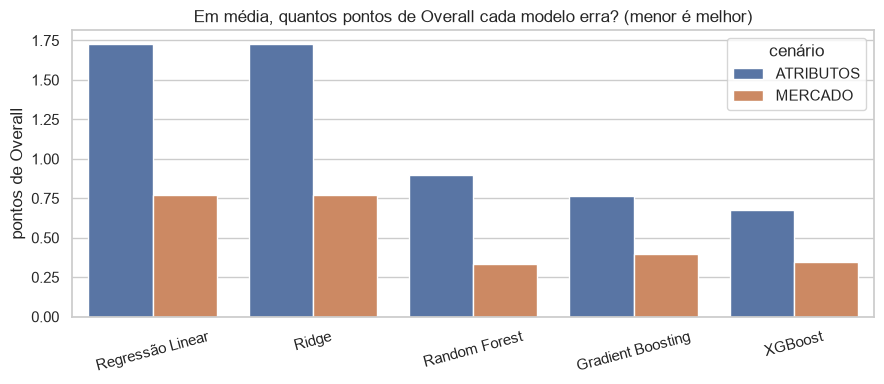

Chutando sempre a média, o erro seria de 5.4 pontos.
O modelo simples (Ridge) erra 1.7 pontos em média.
O melhor modelo (XGBoost) erra só 0.68 ponto em média e explica 98% das diferenças de Overall entre os jogadores.
Com as colunas 'suspeitas' (cenário MERCADO), o erro cairia para 0.35: essa melhora vem de informação que já contém a resposta, por isso não a usamos.


In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=cv_res[cv_res["modelo"] != NOMES["dummy"]], x="modelo", y="erro médio (MAE)", hue="cenário", ax=ax)
ax.set(title="Em média, quantos pontos de Overall cada modelo erra? (menor é melhor)", xlabel="", ylabel="pontos de Overall")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

atr = cv_res[cv_res["cenário"] == "ATRIBUTOS"].set_index("modelo")
mer = cv_res[cv_res["cenário"] == "MERCADO"].set_index("modelo")
melhor = atr.drop(NOMES["dummy"])["erro médio (MAE)"].idxmin()
print(f"Chutando sempre a média, o erro seria de {atr.loc[NOMES['dummy'], 'erro médio (MAE)']:.1f} pontos.")
print(f"O modelo simples (Ridge) erra {atr.loc[NOMES['ridge'], 'erro médio (MAE)']:.1f} pontos em média.")
print(f"O melhor modelo ({melhor}) erra só {atr.loc[melhor, 'erro médio (MAE)']:.2f} ponto em média "
      f"e explica {atr.loc[melhor, 'quanto explica (R²)']:.0%} das diferenças de Overall entre os jogadores.")
print(f"Com as colunas 'suspeitas' (cenário MERCADO), o erro cairia para {mer.loc[melhor, 'erro médio (MAE)']:.2f}: "
      f"essa melhora vem de informação que já contém a resposta, por isso não a usamos.")

**O que isso significa:**
- Todos os modelos são muito melhores que "chutar a média", ou seja, os atributos realmente explicam o Overall.
- Os modelos de **árvores** (Random Forest e principalmente XGBoost) erram **menos da metade** do que o modelo de
  pesos fixos (Ridge). Isso confirma o item 2.2: como cada posição tem a sua "receita", um modelo capaz de combinar
  posição + atributo leva vantagem.
- O cenário MERCADO erra ainda menos, mas é a "prova com gabarito" do item 2.3. Fica registrado como comparação.
- O XGBoost também é rápido de treinar, o que pesa a favor dele quando usarmos a base completa.

### 5.2 E se fizermos um modelo simples para cada posição?
Se o problema do modelo de pesos fixos é misturar posições, uma alternativa é ter **um modelo por posição**
(um só para goleiros, outro só para zagueiros…). Vale testar porque esse tipo de modelo é fácil de explicar:
os pesos mostram diretamente "o quanto cada atributo vale" em cada posição.

In [17]:
def cv_by_group(base_model_fn, data, y, groups, group_col="position_group"):
    """Mesmos 5 simulados, mas treinando um modelo separado para cada posição."""
    preds = np.zeros(len(data))
    for tr, va in cv.split(data, y, groups):
        for g in data[group_col].unique():
            mtr = tr[data.iloc[tr][group_col].values == g]
            mva = va[data.iloc[va][group_col].values == g]
            if len(mva) == 0:
                continue
            mdl = base_model_fn().fit(data.iloc[mtr], y[mtr])
            preds[mva] = mdl.predict(data.iloc[mva])
    return mean_absolute_error(y, preds), r2_score(y, preds)

num_cols, cat_cols = FEATURE_SETS["ATRIBUTOS"]
cat_no_pos = [c for c in cat_cols if c != "position_group"]
mae_g, r2_g = cv_by_group(lambda: Pipeline([("pre", build_preprocess(num_cols, cat_no_pos)), ("m", Ridge(1.0))]),
                          train, y_tr, groups_tr)
print(f"Ridge único para todas as posições: erro médio de {atr.loc[NOMES['ridge'], 'erro médio (MAE)']:.2f} ponto")
print(f"Ridge separado por posição:         erro médio de {mae_g:.2f} ponto")
print(f"Melhor modelo ({melhor}):           erro médio de {atr.loc[melhor, 'erro médio (MAE)']:.2f} ponto")

Ridge único para todas as posições: erro médio de 1.73 ponto
Ridge separado por posição:         erro médio de 0.98 ponto
Melhor modelo (XGBoost):           erro médio de 0.68 ponto


**O que isso significa:** separar por posição melhora bastante o modelo simples. É a prova de que **a EA usa uma
fórmula diferente para cada posição**. Mesmo assim, o XGBoost continua na frente: ele descobre sozinho essas
diferenças e ainda capta detalhes que um modelo de pesos fixos não alcança (por exemplo, o efeito da idade ou do
*skill moves* mudando conforme o nível do jogador).

### 5.3 Ajuste fino do melhor modelo
Todo modelo tem "configurações", como num carro de corrida: quantas árvores usar, qual a profundidade de cada uma,
o quão rápido ele aprende. Testamos combinações dessas configurações (sempre com os 5 simulados) e guardamos a que
erra menos.

In [18]:
N_ITER = 15   # nº de combinações testadas; aumentar na versão final
if HAS_XGB:
    tune_name = NOMES["xgb"]
    param_dist = {"m__n_estimators": [300, 600, 1000], "m__learning_rate": [0.02, 0.05, 0.1],
                  "m__max_depth": [4, 6, 8, 10], "m__min_child_weight": [1, 3, 5],
                  "m__subsample": [0.7, 0.8, 1.0], "m__colsample_bytree": [0.6, 0.8, 1.0],
                  "m__reg_lambda": [0.5, 1, 5]}
else:
    tune_name = NOMES["hgb"]
    param_dist = {"m__max_iter": [300, 600, 1000], "m__learning_rate": [0.02, 0.05, 0.1],
                  "m__max_leaf_nodes": [15, 31, 63, 127], "m__min_samples_leaf": [10, 20, 50],
                  "m__l2_regularization": [0.0, 0.1, 1.0]}

base = make_models(num_cols, cat_cols)[tune_name]
search = RandomizedSearchCV(base, param_dist, n_iter=N_ITER, cv=cv, scoring="neg_mean_absolute_error",
                            random_state=RNG, n_jobs=1, verbose=0)
search.fit(train, y_tr, groups=groups_tr)
best_model = search.best_estimator_
print(f"{tune_name}: erro médio antes do ajuste {atr.loc[tune_name, 'erro médio (MAE)']:.3f} -> "
      f"depois do ajuste {-search.best_score_:.3f} ponto")
print("Configuração escolhida:", {k.replace("m__", ""): v for k, v in search.best_params_.items()})

XGBoost: erro médio antes do ajuste 0.677 -> depois do ajuste 0.654 ponto
Configuração escolhida: {'subsample': 0.8, 'reg_lambda': 1, 'n_estimators': 1000, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


# 6. A prova final
Agora, e só uma vez, usamos os jogadores que ficaram guardados desde o início (seção 4). É o teste mais honesto
possível: o modelo nunca viu nenhum desses jogadores.

In [19]:
def metrics(y, p):
    return {"erro médio (MAE)": mean_absolute_error(y, p),
            "erro c/ peso p/ erros grandes (RMSE)": np.sqrt(mean_squared_error(y, p)),
            "quanto explica (R²)": r2_score(y, p)}

ridge = make_models(num_cols, cat_cols)[NOMES["ridge"]].fit(train, y_tr)
pred_te = best_model.predict(test)
final = {NOMES["dummy"]: metrics(y_te, np.full_like(y_te, y_tr.mean(), dtype=float)),
         NOMES["ridge"]: metrics(y_te, ridge.predict(test)),
         f"{tune_name} (ajustado)": metrics(y_te, pred_te)}
final_df = pd.DataFrame(final).T.round(3)
display(final_df)

fm = final[f"{tune_name} (ajustado)"]
dentro_1 = (np.abs(np.round(pred_te) - y_te) <= 1).mean()
print(f"Na prova final, o {tune_name} errou em média {fm['erro médio (MAE)']:.2f} ponto de Overall.")
print(f"Arredondando a previsão (como no jogo, sem casas decimais), acerta o Overall exato ou erra por "
      f"no máximo 1 ponto em {dentro_1:.0%} dos jogadores.")

,erro médio (MAE),erro c/ peso p/ erros grandes (RMSE),quanto explica (R²)
Chute pela média,5.353,6.850,-0.001
Ridge,1.728,2.210,0.896
XGBoost (ajustado),0.647,0.861,0.984


Na prova final, o XGBoost errou em média 0.65 ponto de Overall.
Arredondando a previsão (como no jogo, sem casas decimais), acerta o Overall exato ou erra por no máximo 1 ponto em 92% dos jogadores.


### 6.1 Metas mínimas (proposta para validar com o grupo)
| Meta | Valor sugerido | Por quê |
|---|---|---|
| Quanto explica (R²) | pelo menos 0,95 (95%) | o Overall é calculado a partir dos atributos, então o modelo deve explicar quase tudo |
| Erro médio (MAE) | até 1 ponto | errar menos de 1 ponto é imperceptível para quem olha a carta |
| Erro médio nos craques (80+) | até 1,5 ponto | garante que o modelo não falha justamente nos jogadores mais importantes |
| Vantagem sobre o modelo simples | erro pelo menos 30% menor que o Ridge | justifica usar um modelo mais complexo |

In [20]:
mae_80 = np.abs(pred_te - y_te)[test["overall_bin"].values == "80+"].mean()
reduc = 1 - fm["erro médio (MAE)"] / final[NOMES["ridge"]]["erro médio (MAE)"]
metas = {
    "Explica pelo menos 95% (R² ≥ 0,95)": fm["quanto explica (R²)"] >= 0.95,
    "Erro médio de até 1 ponto": fm["erro médio (MAE)"] <= 1.0,
    "Erro nos craques 80+ de até 1,5 ponto": mae_80 <= 1.5,
    "Erro pelo menos 30% menor que o Ridge": reduc >= 0.30,
}
for meta, ok in metas.items():
    print(f"{'✅' if ok else '❌'} {meta}")
print(f"\n(erro nos craques: {mae_80:.2f} ponto | redução de erro vs. Ridge: {reduc:.0%})")

✅ Explica pelo menos 95% (R² ≥ 0,95)
✅ Erro médio de até 1 ponto
✅ Erro nos craques 80+ de até 1,5 ponto
✅ Erro pelo menos 30% menor que o Ridge

(erro nos craques: 0.78 ponto | redução de erro vs. Ridge: 63%)


### 6.2 Onde o modelo erra mais?
Olhamos o erro separado por faixa de Overall e por posição. O **viés** indica a direção do erro: negativo quer dizer
que o modelo costuma **dar nota menor** do que a real; positivo, que costuma **dar nota maior**.

,jogadores,erro_medio,vies
overall_bin,,,
<60,615,0.77,0.23
60-69,2008,0.61,-0.01
70-79,911,0.63,-0.13
80+,92,0.78,-0.18


,jogadores,erro_medio,vies
position_group,,,
DEF,1197,0.59,-0.04
FWD,695,0.63,-0.01
GK,427,0.44,0.03
MID,1307,0.77,0.03


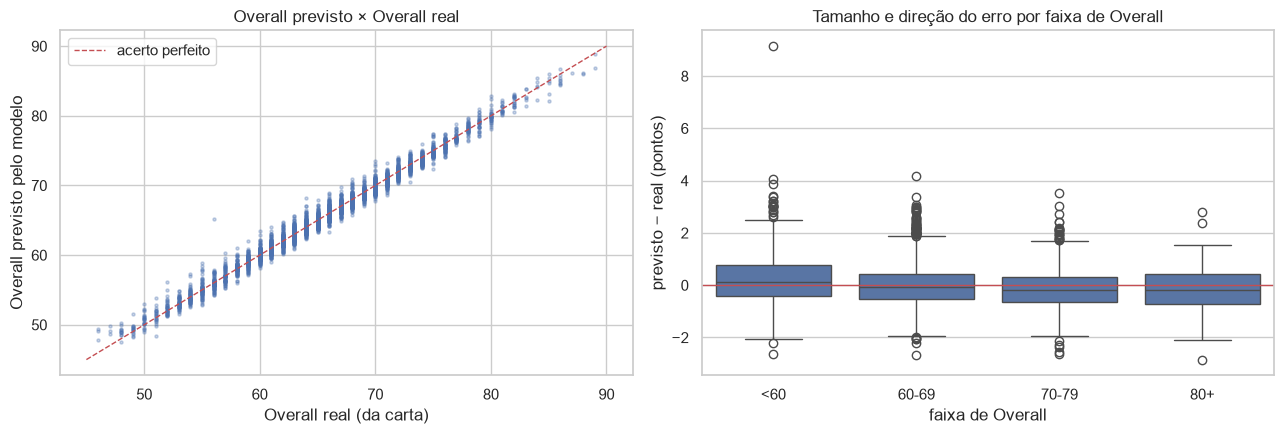

In [21]:
ev = test.assign(pred=pred_te, err=pred_te - y_te, abs_err=np.abs(pred_te - y_te))
tbl_bin = ev.groupby("overall_bin", observed=True).agg(jogadores=("err", "size"), erro_medio=("abs_err", "mean"),
                                                       vies=("err", "mean")).round(2)
tbl_pos = ev.groupby("position_group", observed=True).agg(jogadores=("err", "size"), erro_medio=("abs_err", "mean"),
                                                          vies=("err", "mean")).round(2)
display(tbl_bin); display(tbl_pos)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_te, pred_te, s=5, alpha=.3)
lims = [y_te.min() - 1, y_te.max() + 1]
axes[0].plot(lims, lims, "r--", lw=1, label="acerto perfeito")
axes[0].set(title="Overall previsto × Overall real", xlabel="Overall real (da carta)", ylabel="Overall previsto pelo modelo")
axes[0].legend()
sns.boxplot(data=ev, x="overall_bin", y="err", ax=axes[1], color="#4C72B0")
axes[1].axhline(0, color="r", lw=1)
axes[1].set(title="Tamanho e direção do erro por faixa de Overall",
            xlabel="faixa de Overall", ylabel="previsto − real (pontos)")
plt.tight_layout(); plt.show()

**O que isso significa:**
- No gráfico da esquerda, quanto mais perto da linha vermelha, melhor. Os pontos ficam colados nela em toda a escala.
- Nos extremos, o modelo tende a **puxar para o meio**: dá nota um pouco maior para os jogadores mais fracos e um
  pouco menor para os craques. É um comportamento conhecido, porque ele viu muito mais jogadores medianos do que
  estrelas (item 2.6). Mesmo assim, o erro nos craques fica abaixo de 1 ponto.
- O goleiro é a posição em que o modelo acerta mais, o que faz sentido: a nota do goleiro depende de poucos
  atributos (os de goleiro) e por isso é mais "previsível".

# 7. O que o modelo "olha" para decidir o Overall?
Para descobrir quais informações o modelo mais usa, fazemos um teste simples: **embaralhamos uma coluna por vez**
(por exemplo, trocamos os valores de Reações entre os jogadores) e medimos quanto o erro piora. Se piorar muito,
aquela informação é essencial para o modelo.

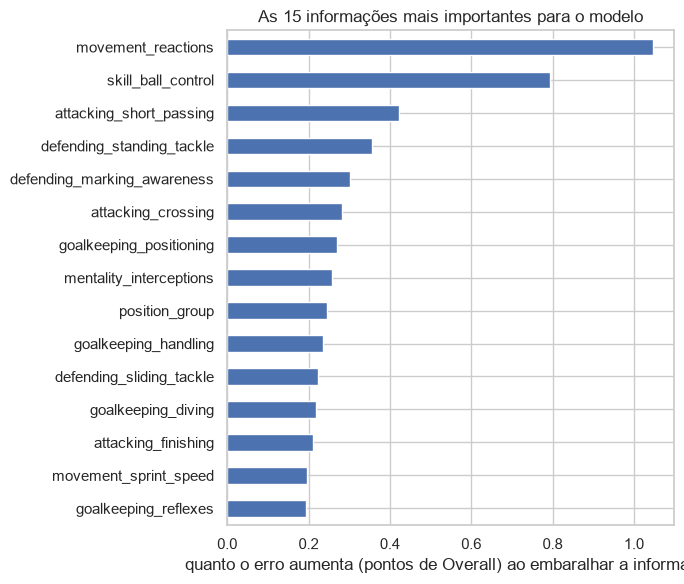

Top 5: movement_reactions, skill_ball_control, attacking_short_passing, defending_standing_tackle, defending_marking_awareness


In [22]:
samp = test.sample(min(3000, len(test)), random_state=RNG)
pi = permutation_importance(best_model, samp[num_cols + cat_cols], samp[TARGET].values,
                            n_repeats=5, random_state=RNG, scoring="neg_mean_absolute_error", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=num_cols + cat_cols).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 6))
imp.head(15)[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set(title="As 15 informações mais importantes para o modelo",
       xlabel="quanto o erro aumenta (pontos de Overall) ao embaralhar a informação")
plt.tight_layout(); plt.show()
print("Top 5:", ", ".join(imp.head(5).index))

**O que isso significa:** se as informações mais importantes fazem sentido para quem conhece o jogo (no resultado:
Reações, Controle de bola, Passe curto, Desarme em pé e Marcação), temos mais um sinal de que o modelo aprendeu a lógica do Overall,
e não uma coincidência dos dados.

*Observação:* quando dois atributos dizem coisas parecidas (como Desarme em pé e Carrinho), a importância se divide
entre eles, e cada um pode parecer menos importante do que realmente é.

# 8. Conclusão: por que recomendamos este modelo
*(revisar os números depois de rodar com a base completa FIFA 15–23)*

1. **Ele funciona:** sem ver o Overall, só com os atributos, o modelo acerta a nota com erro médio abaixo de
   1 ponto, muito melhor do que chutar a média ou usar uma fórmula de pesos fixos.
2. **O teste foi justo:** a nota vem de jogadores que o modelo nunca viu, sem nenhuma coluna que "entrega a resposta"
   (ratings por posição, Potencial, valor e salário ficaram de fora).
3. **Ele entende o jogo:** os resultados confirmam que cada posição tem a sua "receita" de Overall, e o modelo
   escolhido é justamente o que melhor capta essa diferença.
4. **Limitação conhecida:** tende a "puxar para o meio" nos extremos (craques e jogadores muito fracos), ainda com
   erro pequeno. Uma melhoria futura é dar mais peso aos craques durante o treino.
5. **Próximos passos:** rodar com a base completa e ferramentas próprias para grandes volumes de dados.

## Declaração de uso de IA
> Durante a preparação deste Projeto, os autores utilizaram o **Claude (Anthropic)** como apoio para discussão de
> conceitos, estruturação da análise e revisão de código. Após usar essa ferramenta, os autores revisaram e editaram
> o conteúdo conforme necessário e assumem **total responsabilidade** pelo conteúdo.
> *(Conforme Resolução CONSUN PUCPR 274/2024, item 2-IX. A IA não é coautora.)*